<img src="./logo_UTN.svg" align="right" width="150" /> 

#### Teoría de los Circuitos 2

# **Tarea Semanal 6**
#### Nahuel Siles

A continuación se muestran 2 circuitos conocidos en un esquema de 3 nodos externos. Tener en cuenta que para el análisis de la red se pueden definir nodos internos.

<img src='Redes.PNG'/>

Se pide:

1. Construir la ***Matriz Admitancia Indefinida*** para cada caso. En el **BS170** plantear el modelo lineal visto en clase con admitancias y generadores de corriente, que tenga en cuenta: $C_{iss}$, $C_{oss}$, $C_{rss}$ y $g_m$

2. Para la red T se pide:
   
   a ) Obtener $\frac{V_{23}}{V_{13}}$ ; $\frac{V_{21}}{V_{31}}$ y $\frac{V_{12}}{V_{32}}$, explicitando el armado de los cofactores de segundo orden.
   
   b ) Graficar y observar detenidamente la respuesta de módulo y fase para cada transferencia. Analizar si entre 2 de las transferencias halladas se cumple que son complementarias en módulo : $|T_a + T_b| = 1$

3. Para el MOS se pide:
   
   a ) Dada la MAI hallada en 1 obtener los parámetros $Y$ para las configuraciones *source común* y *drain común*.
   
   b ) Calcular la matriz de parámetros $ABCD$ en configuración source común.

Propiedades de la *MAI*:

* La sumatoria de filas es igual a cero.
* La sumatoria de columnas es igual a cero.
* El determinante de la matriz es igual a cero.
* Todos los cofactores de primer orden son iguales, es decir: $Y_j^i = Y_m^n$


**Bonus**

1. Implementar en Python el armado de la MAI y la obtención de 2a) con los módulos disponibles en pytc2

2. Simulación Circuital y medición de los parámetros $Y$ del MOS en configuración drain común. Implementar el modelo SPICE del *BS170*:

### **Módulos de Python**

In [1]:
# Módulos numéricos y de funciones científicas
import numpy as np
from scipy import signal as sig
import sympy as sp
from IPython.display import display, Math

# Módulos para los gráficos
import matplotlib as mpl
from matplotlib import pyplot as plt

# Funciones de PyTC2
from pytc2.sistemas_lineales import bodePlot, pzmap, GroupDelay, analyze_sys, tf2sos_analog, pretty_print_SOS
from pytc2.general import print_latex, print_subtitle, a_equal_b_latex_s
from pytc2.cuadripolos import calc_MAI_vtransf_ij_mn

#Tamaño de los gráficos
fig_sz_x = 13
fig_sz_y = 7
fig_dpi = 80 # dpi

fig_font_size = 11

mpl.rcParams['figure.figsize'] = (fig_sz_x, fig_sz_y)
mpl.rcParams['figure.dpi'] = fig_dpi
plt.rcParams.update({'font.size':fig_font_size})

### **Resolución**

### **MAI de la red T y cofactores**

La matriz de admitancia indefinida de una red T es la siguiente:

$$
Y_{MAI}=
\begin{bmatrix}
Y_L   &   0           &   0   &   -Y_L     \\
0              & Y_L  &   0   &   -Y_L      \\
0              &   0           &   Y_C  &      -Y_C             \\
-Y_L  & -Y_L &  -sC  &   2Y_L + Y_C
\end{bmatrix}
$$

La relación general de transferencia mediante la MAI es:

$$T = \frac{V_{ij}}{V_{mn}} = S \frac{Y_{mn}^{ij}}{Y_{mn}^{mn}}$$

Donde $Y_{mn}^{ij}$ e $Y_{mn}^{mn}$ representan los cofactores de segundo orden. Estos se obtiene al eliminar las filas $i, j$ y $m, n$, y columnas $m, n$.

$S$ representa la función de corrección de signo la cual puede ser:

$S = (-1)^{(j+k+m+n)}$

$S = sgn(i-j)sgn(m-n)$

Si uan no funciona utilizamos la otra.

Entonces para las transferencias pedidas:

$$
\frac{V_{23}}{V_{13}} = \frac{ Y_{23}^{13} }{ Y_{13}^{13} }
$$

$$
\frac{V_{21}}{V_{31}} = \frac{ Y_{21}^{31} }{ Y_{31}^{31} }
$$

$$
\frac{V_{12}}{V_{32}} = \frac{ Y_{12}^{32} }{ Y_{32}^{32} }
$$

Donde el cofactor $Y_{23}^{13}$ es:

$Y_{23}^{13} = (-1)^{(2+3+1+3)}det
\begin{pmatrix}
0   &  -Y_L   \\
-Y_L  &  2Y_L+Y_C \\
\end{pmatrix}
$

$Y_{23}^{13} = (-1)^{(9)}( 0 - Y_L^2 )$

$$Y_{23}^{13} =  Y_L^2 $$

Donde el cofactor $Y_{13}^{13}$ es:

$Y_{13}^{13} = (-1)^{(1+3+1+3)}det
\begin{pmatrix}
Y_L   &  -Y_L   \\
-Y_L  &  2Y_L+Y_C \\
\end{pmatrix}
$

$Y_{13}^{13} = (-1)^{(8)}( Y_L(2Y_L+Y_C) - Y_L^2 )$

$Y_{13}^{13} = (1)( 2Y_L^2+Y_CY_L - Y_L^2 )$

$$Y_{13}^{13} = ( Y_L^2+Y_CY_L )$$

Donde el cofactor $Y_{21}^{31}$ es:

$Y_{21}^{31} = (-1)^{(2+1+3+1)}det
\begin{pmatrix}
0   &  -Y_C   \\
-Y_L  &  2Y_L+Y_C \\
\end{pmatrix}
$

$Y_{21}^{31} = (-1)^{(7)}( 0 - Y_LY_C )$

$$Y_{21}^{31} =  Y_LY_C $$


El cofactor $Y_{31}^{31}$ es igual al cofactor $Y_{13}^{13}$

El cofactor $Y_{12}^{32}$ es:

$Y_{12}^{32} = (-1)^{(1+2+3+2)}det
\begin{pmatrix}
0   &  -Y_L   \\
-Y_C  &  2Y_L+Y_C \\
\end{pmatrix}
$

$Y_{12}^{32} = (-1)^{(8)}( 0 - Y_CY_L )$

$$Y_{12}^{32} =  -Y_CY_L $$

El cofactor $Y_{32}^{32}$ es:

$Y_{32}^{32} = (-1)^{(3+2+3+2)}det
\begin{pmatrix}
Y_L   &  -Y_C   \\
-Y_C  &  2Y_L+Y_C \\
\end{pmatrix}
$

$Y_{32}^{32} = (-1)^{(10)}( Y_L(2Y_L+Y_C) - Y_L^2 )$

$Y_{32}^{32} = (1)( 2Y_L^2+Y_CY_L - Y_L^2 )$

$$Y_{32}^{32} =  Y_L^2+Y_CY_L $$

#### **Obtención de transferencias con módulo y fase**

##### Transferencia $T_{13}^{23} = \frac{V_{23}}{V_{13}}$

Finalmente presentamos nuestras transferencias, junto a sus respectivas simulaciones, que quedan de la siguiente manera:

$$
\frac{V_{23}}{V_{13}} = \frac{ Y_L^2 }{ Y_L^2+Y_CY_L } = \frac{ Y_L }{ Y_L+Y_C }
$$

In [23]:
YL, YC = sp.symbols('YL YC', complex=True)

# Armo la MAI
#            Nodos:   0       1         2              3
Ymai = sp.Matrix([  
                    [ YL,      0,      0,           -YL],
                    [ 0,      YL,      0,           -YL],
                    [ 0,       0,     YC,           -YC],
                    [ -YL,   -YL,    -YC,      2*YL+YC ]
                 ])

Vmai = calc_MAI_vtransf_ij_mn(Ymai, 1, 2, 0, 2)

print_latex( r'T^{{ {:d}{:d} }}_{{ {:d}{:d} }} = '.format( 2, 3, 1, 3) +  sp.latex(Vmai) )

<IPython.core.display.Math object>

$$
\frac{ Y_L }{ Y_L+Y_C } = \frac{\frac{1}{sL}}{\frac{1}{sL} + sC} = \frac{1}{s^2 LC + 1} = \frac{\frac{1}{LC}}{s^2 + \frac{1}{LC}} 
$$

$$
T_{13}^{23} = \frac{V_{23}}{V_{13}} = \frac{\frac{1}{LC}}{s^2 + \frac{1}{LC}} 
$$

Normalizado:

$$
T_{13}^{23} = \frac{V_{23}}{V_{13}} = \frac{1}{s^2 + 1} 
$$

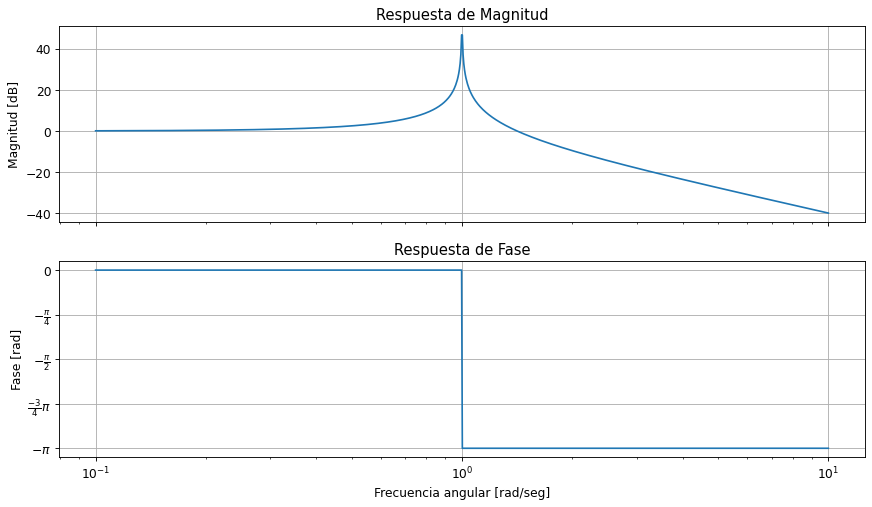

In [18]:
w0 = 1

num = np.array([ w0**2 ])
den = np.array([ 1, 0, w0**2])

H1 = sig.TransferFunction( num, den )

_ = bodePlot(H1)

##### Transferencia $T_{31}^{21} = \frac{V_{21}}{V_{31}}$

$$
\frac{V_{21}}{V_{31}} = \frac{ Y_LY_C }{ Y_L^2+Y_CY_L } = \frac{ Y_C }{ Y_L+Y_C }
$$

In [22]:
YL, YC = sp.symbols('YL YC', complex=True)

# Armo la MAI
#            Nodos:   0       1         2              3
Ymai = sp.Matrix([  
                    [ YL,      0,      0,           -YL],
                    [ 0,      YL,      0,           -YL],
                    [ 0,       0,     YC,           -YC],
                    [ -YL,   -YL,    -YC,      2*YL+YC ]
                 ])

Vmai = calc_MAI_vtransf_ij_mn(Ymai, 1, 0, 2, 0)

print_latex( r'T^{{ {:d}{:d} }}_{{ {:d}{:d} }} = '.format( 2, 1, 3, 1) +  sp.latex(Vmai))

<IPython.core.display.Math object>

$$\frac{ Y_C }{ Y_L+Y_C } = \frac{sC}{\frac{1}{sL} + sC} = \frac{s^2 LC}{s^2 LC + 1} = \frac{s^2}{s^2 + \frac{1}{LC}}$$

$$
T_{31}^{21} = \frac{V_{21}}{V_{31}} = \frac{s^2}{s^2 + \frac{1}{LC}}
$$

Normalizado:

$$
T_{31}^{21} = \frac{V_{21}}{V_{31}} = \frac{s^2}{s^2 + 1}
$$

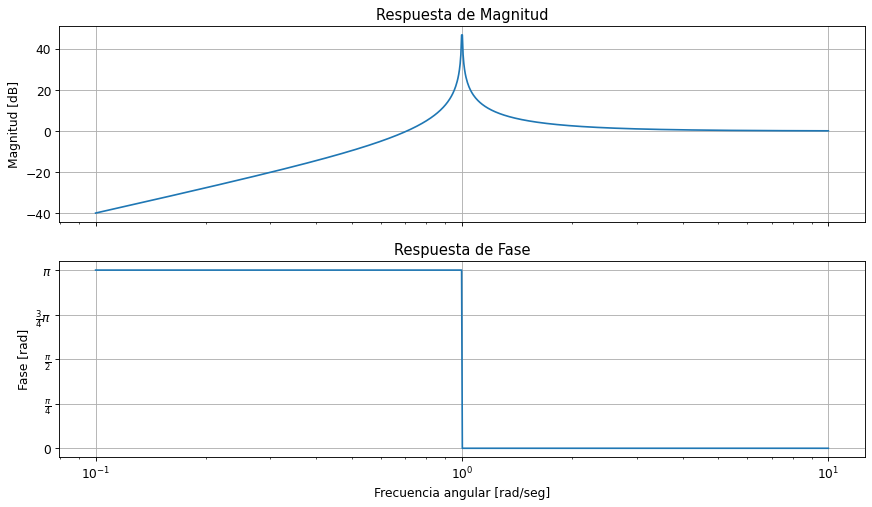

In [20]:
w0 = 1

num = np.array([ 1, 0, 0])
den = np.array([ 1, 0, w0**2])

H1 = sig.TransferFunction( num, den )

_ = bodePlot(H1)

##### Transferencia $T_{32}^{12} = \frac{V_{12}}{V_{32}}$

$$
\frac{V_{12}}{V_{32}} = \frac{ Y_CY_L }{ Y_L^2+Y_CY_L } = \frac{ Y_C }{ Y_L+Y_C }
$$

In [21]:
YL, YC = sp.symbols('YL YC', complex=True)

# Armo la MAI
#            Nodos:   0       1         2              3
Ymai = sp.Matrix([  
                    [ YL,      0,      0,           -YL],
                    [ 0,      YL,      0,           -YL],
                    [ 0,       0,     YC,           -YC],
                    [ -YL,   -YL,    -YC,      2*YL+YC ]
                 ])

Vmai = calc_MAI_vtransf_ij_mn(Ymai, 0, 1, 2, 1)

print_latex( r'T^{{ {:d}{:d} }}_{{ {:d}{:d} }} = '.format( 1, 2, 3, 2) +  sp.latex(Vmai))

<IPython.core.display.Math object>

$$\frac{ Y_C }{ Y_L+Y_C } = \frac{sC}{\frac{1}{sL} + sC} = \frac{s^2 LC}{s^2 LC + 1} = \frac{s^2}{s^2 + \frac{1}{LC}}$$

$$
T_{32}^{12} = \frac{V_{12}}{V_{32}} = \frac{s^2}{s^2 + \frac{1}{LC}}
$$

Normalizado:

$$
T_{32}^{12} = \frac{V_{12}}{V_{32}} = \frac{s^2}{s^2 + 1}
$$

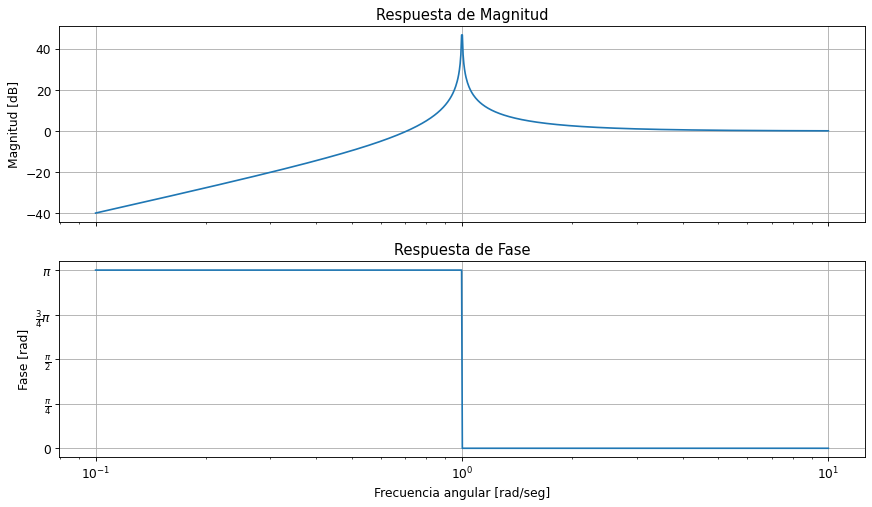

In [24]:
w0 = 1

num = np.array([ 1, 0, 0])
den = np.array([ 1, 0, w0**2])

H1 = sig.TransferFunction( num, den )

_ = bodePlot(H1)

#### Análisis de las transferencias obtenidas

Las transferencias obtenidas son:
$$
T_{13}^{23} = \frac{1}{s^2 + 1} 
$$

$$
T_{31}^{21} = \frac{s^2}{s^2 + 1}
$$

$$
T_{32}^{12} = \frac{s^2}{s^2 + 1}
$$

Podemos notar que $T_{13}^{23}$ es complementaria con $T_{31}^{21}$ y con $T_{32}^{12}$

$$
H(s) = T_{13}^{23} + T_{31}^{21} = \frac{s^2}{s^2 + 1} + \frac{1}{s^2 + 1} = 
\frac{s^2 + 1}{s^2 + 1} = 1
$$

Vemos entonces que la suma de ambas da 1

### **MAI de la red MOS**

La red equivalente del MOSFET es el siguiente:

<img src="MOSFET_cuadripolo.PNG"/>

En el datasheet de los MOSFET, las capacitancias se especifican mediante las de entrada, salida y transferencia en cortocircuito:

* **Capacitancia de transferencia inversa:** $C_{rss} = C_{GD}$
* **Capacitancia de entrada (Source común):** $C_{iss} = C_{GS} + C_{GD} \implies \mathbf{C_{GS} = C_{iss} - C_{rss}}$
* **Capacitancia de salida (Source común):** $C_{oss} = C_{DS} + C_{GD} \implies \mathbf{C_{DS} = C_{oss} - C_{rss}}$

Definimos los nodos de la siguiente manera:

* **Nodo 1:** Gate (G)
* **Nodo 2:** Drain (D)
* **Nodo 3:** Source (S)

Las admitancias de cada capacitancia queda entonces:

* $Y_{GS} = s C_{GS} = s(C_{iss} - C_{rss})$
* $Y_{GD} = s C_{GD} = s C_{rss}$
* $Y_{DS} = s C_{DS} = s(C_{oss} - C_{rss})$

Obtendremos los parámetros de la MAI por filas:

**Fila 1 (Nodo Gate):**
   * $Y_{11}$ = $Y_{GS} + Y_{GD} = s(C_{GS} + C_{GD}) = \mathbf{s C_{iss}}$
   * $Y_{12}$ = $-Y_{GD} = \mathbf{-s C_{rss}}$
   * $Y_{13}$ = $-Y_{GS} = \mathbf{-s (C_{iss} - C_{rss})}$

**Fila 2 (Nodo Drain):**

Corriente generada por la fuente dependiente: $i_D = g_m v_{gs} = g_m (v_1 - v_3)$
   * $Y_{21}$ = $-Y_{GD} + g_m = \mathbf{g_m - s C_{rss}}$
   * $Y_{22}$ = $Y_{GD} + Y_{DS} = s(C_{GD} + C_{DS}) = \mathbf{s C_{oss}}$
   * $Y_{23}$ = $-Y_{DS} - g_m = \mathbf{-(g_m + s(C_{oss} - C_{rss}))}$

**Fila 3 (Nodo Source):**

Obtenida por propiedad de suma cero en columnas:
   * $Y_{31} = -(Y_{11} + Y_{21}) = \mathbf{-(g_m + s(C_{iss} - C_{rss}))}$
   * $Y_{32} = -(Y_{12} + Y_{22}) = s C_{rss} - s C_{oss} = \mathbf{-s (C_{oss} - C_{rss})}$
   * $Y_{33} = -(Y_{13} + Y_{23}) = \mathbf{g_m + s (C_{iss} + C_{oss} - 2C_{rss})}$

La MAI queda entonces como:

$$
Y_{MAI}=
\begin{bmatrix}
sC_{iss}                    &   -sC_{rss}            &  -s(C_{iss} - C_{rss})                 \\
gm-sC_{rss}                 &   sC_{oss}             &  -(g_m + s(C_{oss} - C_{rss}))         \\
-(gm + s(C_{iss}-C_{rss}))  &   -s(C_{oss}-C_{rss})  &  g_m + s(C_{iss} + C_{oss} -2C_{rss})  \\
\end{bmatrix}
$$

#### **Parámetros Y en *source común***

Para obtener la MAI en configuración *source común* eliminamos la fila y columna correspondiente al nodo de dicha configuración. En este caso la fila 3 y columna 3:

$$
Y_{SC}=
\begin{bmatrix}
sC_{iss}           &   -sC_{rss}        \\
gm-sC_{rss}        &   sC_{oss}         \\
\end{bmatrix}
$$

#### **Parámetros Y en *drain común***

Para obtener la MAI en configuración *drain común* eliminamos la fila y columna correspondiente al nodo de dicha configuración. En este caso la fila 2 y columna 2:

$$
Y_{DC}=
\begin{bmatrix}
sC_{iss}                      &  -s(C_{iss} - C_{rss})                 \\
-(gm + s(C_{iss}-C_{rss}))    &  g_m + s(C_{iss} + C_{oss} -2C_{rss})  \\
\end{bmatrix}
$$

#### **Matriz de parámetros ABCD en *source común***

La estructura de red de dos puertos en parámetros ABCD de define como:

$$
\begin{bmatrix} V_1 \\ I_1 \end{bmatrix} = \begin{bmatrix} A & B \\ C & D \end{bmatrix}
                                           \begin{bmatrix} V_2   \\ -I_2  \end{bmatrix}
$$

Al ser una matriz de 2x2 conocemos la relación de conversión desde una matriz de admitancia:

* $A = -\frac{Y_{22}}{Y_{21}}$
* $B = -\frac{1}{Y_{21}}$
* $C = -\frac{ \det(Y_{SC}) }{Y_{21}}$
* $D = -\frac{Y_{11}}{Y_{21}}$

Calculando primero el determinate de $Y_{SC}$:

$$
\det(Y_{SC}) = y_{11} y_{22} - y_{12} y_{21} = (s C_{iss})(s C_{oss}) - (-s C_{rss})(g_m - s C_{rss})
$$

$$
\det(Y_{SC}) = s^2 C_{iss} C_{oss} + s C_{rss} g_m - s^2 C_{rss}^2 = s [ g_m C_{rss} + s (C_{iss} C_{oss} - C_{rss}^2)]
$$

$$\det(Y_{SC}) = s [ g_m C_{rss} + s (C_{iss} C_{oss} - C_{rss}^2)] $$

Entonces la matriz de transmisión ABCD queda:

$$
T_{SC} = \frac{1}{s C_{rss} - g_m} 
\begin{bmatrix}
s C_{oss}                                             &    1              \\ 
s [ g_m C_{rss} + s(C_{iss} C_{oss} - C_{rss}^2) ]    &    s C_{iss}
\end{bmatrix}
$$
